# OpenClassrooms - parcours Data Analyst Business Intelligence - P8

# Milestone 1 - Analyse des données

Dans cette partie nous allons analyser le jeu de données que nous avons à notre disposition. Notre objectif est de comprendre les relations entre les variables, et surtout, celles qui influent sur le prix des transactions immobilières. Grâce à ce travail, nous pourrons ne conserver que les variables qui seront utiles à l'apprentissage de notre algorithme.

## 1.Type des données

La première étape à réaliser est d'importer les données dans le notebook et d'opérer des transformations sur les variables si celles-ci s'imposent (exemple : nettoyage ou changement de type des variables, etc.).

In [37]:
#On importe les librairies que nous utiliserons pour traiter les données et les visualiser
import pandas as pd, numpy as np
# N'oubliez pas d'avoir installé les librairies pandas, numpy et matplotlib via la commande pip

In [38]:
#On importe les données dans un dataframe
df = pd.read_excel('historique_immobilier_paris_2017_2021_vdef2.xlsx')
df.head()

,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,code_type_local,type_local,surface_reelle
0,2017-01-03,5.505597e+05,8,RUE DES COUTURES SAINT GERVAIS,75003,Paris 3e Arrondissement,2,Appartement,50
1,2017-01-12,1.576492e+06,32,AV MARCEAU,75008,Paris 8e Arrondissement,2,Appartement,163
2,2017-01-10,6.577574e+05,52,RUE DU FAUBOURG SAINT HONORE,75008,Paris 8e Arrondissement,2,Appartement,66
3,2017-01-10,2.500868e+05,64,RUE DU VERTBOIS,75003,Paris 3e Arrondissement,2,Appartement,22
4,2017-01-13,1.762667e+05,25,RUE DES LAVANDIERES STE OPPORT,75001,Paris 1er Arrondissement,2,Appartement,15


Attention, si l'opération ci-dessus ne marche pas, il se peut que le package "openpyxl" ne soit pas présent sur votre ordinateur. Si c'est le cas vous pouvez l'installer en éxécutant la commande : pip install openpyxl ou conda install openpyxl.

On contrôle ensuite deux pièges classiques du nettoyage : les **valeurs manquantes** (`isna().sum()`) et les **doublons** (`duplicated().sum()`).

In [39]:
#On vérifie que le type des données attribué par pandas est cohérent
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26196 entries, 0 to 26195
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date_mutation     26196 non-null  datetime64[us]
 1   valeur_fonciere   26196 non-null  float64       
 2   adresse_numero    26196 non-null  int64         
 3   adresse_nom_voie  26196 non-null  str           
 4   code_postal       26196 non-null  int64         
 5   nom_commune       26196 non-null  str           
 6   code_type_local   26196 non-null  int64         
 7   type_local        26196 non-null  str           
 8   surface_reelle    26196 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(4), str(3)
memory usage: 1.5 MB


In [40]:
# Valeurs manquantes par colonne
print(df.isna().sum())

# Lignes en double (toutes les colonnes identiques)
print('\nNombre de doublons :', df.duplicated().sum())

date_mutation       0
valeur_fonciere     0
adresse_numero      0
adresse_nom_voie    0
code_postal         0
nom_commune         0
code_type_local     0
type_local          0
surface_reelle      0
dtype: int64

Nombre de doublons : 16


**Conclusion :** les types attribués par pandas sont cohérents : `date_mutation` est bien reconnue comme une date, `valeur_fonciere` et `surface_reelle` sont numériques. Il n'y a **aucune valeur manquante**. On repère **16 lignes en double** (même date, même adresse, même prix, même surface) : sur 26 196 lignes c'est négligeable (0,06 %), et comme on ne peut pas exclure deux ventes réelles identiques (ex. deux lots dans un même immeuble), on les **conserve** et on le signale.

### 2. Regardons les différents types de biens immobiliers que nous avons dans nos données :

In [41]:
print('la liste des différents types de biens immobiliers que nous avons dans les données est :')
print(df['type_local'].unique())
df[['code_type_local','type_local']].drop_duplicates()

la liste des différents types de biens immobiliers que nous avons dans les données est :
<StringArray>
['Appartement', 'Local industriel. commercial ou assimilé']
Length: 2, dtype: str


,code_type_local,type_local
0,2,Appartement
18,4,Local industriel. commercial ou assimilé


On observe qu'il y a **2 types de biens**, et que leurs codes types sont **2 (Appartement)** et **4 (Local industriel, commercial ou assimilé)**.

### 3. Nombre de transactions

In [42]:
#On verifie le nombre de transactions que nous avons dans notre dataframe
print('le nombre de transactions dans les données est', len(df))
print('le nombre de transactions pour les appartements dans les données est', len(df[df['code_type_local'] == 2]))
print('le nombre de transactions pour les locaux commerciaux dans les données est', len(df[df['code_type_local'] == 4]))

# Vérification en une ligne
df['type_local'].value_counts()

le nombre de transactions dans les données est 26196
le nombre de transactions pour les appartements dans les données est 24353
le nombre de transactions pour les locaux commerciaux dans les données est 1843


type_local
Appartement                                 24353
Local industriel. commercial ou assimilé     1843
Name: count, dtype: int64

Les appartements représentent **93 %** des transactions (24 353 sur 26 196) et les locaux commerciaux **7 %** (1 843). Ce déséquilibre est à garder en tête : les conclusions sur les locaux reposent sur beaucoup moins de données.

### 4. interval de l'historique des données

In [43]:
#On vérifie également la plage de l'historique disponible
print('la première date de transaction dans les données est le', df['date_mutation'].min().date())
print('la dernière date de transaction dans les données est le', df['date_mutation'].max().date())

la première date de transaction dans les données est le 2017-01-02
la dernière date de transaction dans les données est le 2021-12-31


L'historique couvre donc **5 années complètes**, du 2 janvier 2017 au 31 décembre 2021.

## Commençons à analyser les données

Maintenant nous allons analyser les données historiques pour les 2 différents types de biens immobiliers en essayant d'identifier les relations entre les variables. Mais avant cela, il nous faudra pouvoir comparer les biens entre eux, et pour cela nous allons créer une colonne du prix au metre carré.

In [44]:
# Calcul de la colonne
df['prix_m2'] = df['valeur_fonciere'] / df['surface_reelle']
df['annee'] = df['date_mutation'].dt.year
df[['valeur_fonciere','surface_reelle','prix_m2','annee']].head()

,valeur_fonciere,surface_reelle,prix_m2,annee
0,5.505597e+05,50,11011.193562,2017
1,1.576492e+06,163,9671.732877,2017
2,6.577574e+05,66,9966.020548,2017
3,2.500868e+05,22,11367.582877,2017
4,1.762667e+05,15,11751.113836,2017


Maintenant, analysons les appartements.

### 5. Evolution du prix au metre carré des appartements dans Paris

In [45]:
#On retire les colonnes qui sont à priori inutiles ET nous allons nous concentrer sur les appartements dans un premier temps
df_appart = df[df['code_type_local'] == 2].drop(columns=['adresse_numero','adresse_nom_voie','nom_commune','type_local'])
df_appart.head()

,date_mutation,valeur_fonciere,code_postal,code_type_local,surface_reelle,prix_m2,annee
0,2017-01-03,5.505597e+05,75003,2,50,11011.193562,2017
1,2017-01-12,1.576492e+06,75008,2,163,9671.732877,2017
2,2017-01-10,6.577574e+05,75008,2,66,9966.020548,2017
3,2017-01-10,2.500868e+05,75003,2,22,11367.582877,2017
4,2017-01-13,1.762667e+05,75001,2,15,11751.113836,2017


In [46]:
#Préparons un dataframe en regroupant les prix moyens de ventes des appartements par année avec la surface moyenne associée
df_annee = df_appart.groupby('annee')[['valeur_fonciere','surface_reelle','prix_m2']].mean().round(2).reset_index()
df_annee

,annee,valeur_fonciere,surface_reelle,prix_m2
0,2017,427963.24,44.63,9492.86
1,2018,448055.76,44.27,10031.40
2,2019,461950.06,43.36,10562.71
3,2020,462383.25,42.90,10674.87
4,2021,458771.51,43.48,10455.60


On constate sur la moyenne des prix de vente des appartements à Paris que **le prix au m² augmente régulièrement de 2017 à 2020** (de 9 493 € à 10 675 €, soit +12 %), puis **baisse légèrement en 2021** (10 456 €, environ -2 %), probablement un effet de la crise sanitaire. La surface moyenne reste stable autour de 43-45 m². <br>
Nous allons créer un graphique pour mieux le visualiser.

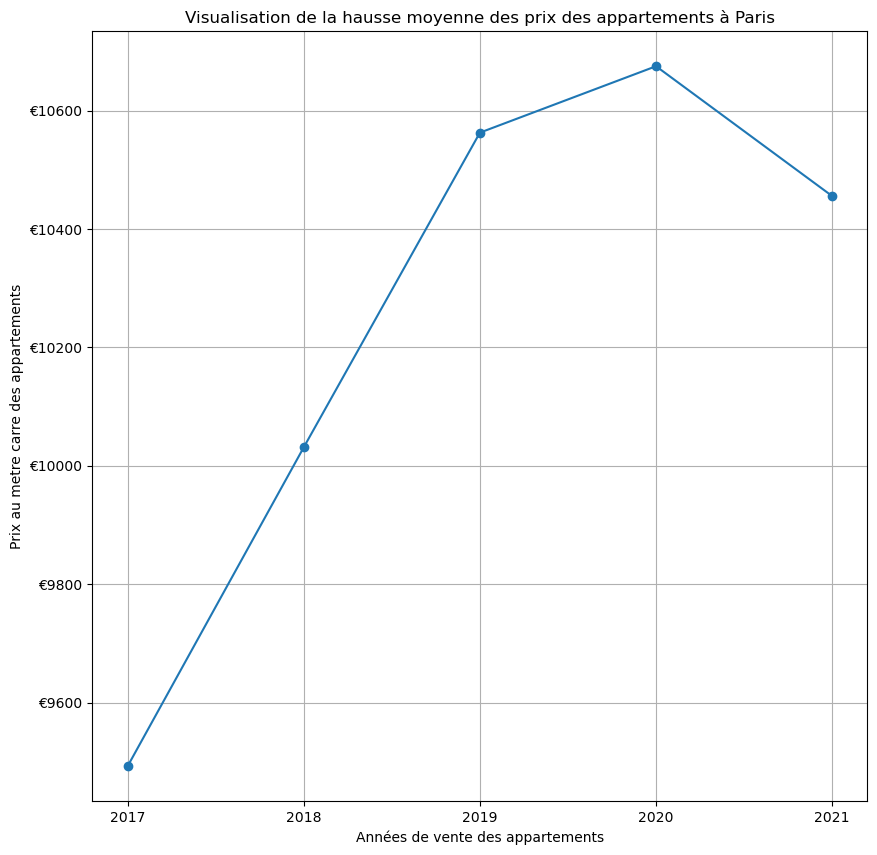

In [47]:
#Création d'un graphique pour visualiser la hausse de la moyenne des prix
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
plt.figure(figsize=(10,10))
plt.plot(['2017','2018','2019','2020','2021'], df_annee['prix_m2'], marker='o')
plt.xlabel('Années de vente des appartements')
plt.ylabel('Prix au metre carre des appartements')
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)
plt.grid()
plt.title('Visualisation de la hausse moyenne des prix des appartements à Paris')
plt.show()

### 6. Différences de prix au metre carré entre les arrondissements

Maintenant nous allons chercher à afficher l'évolution des prix par arrondissement. Vérifions la liste des arrondissements que nous avons dans nos données. Normalement à Paris nous avons 20 codes postaux différents, 1 par arrondissement allant de 75001 à 75020.

In [48]:
#Liste des codes postaux dans nos données.
print(sorted(df_appart['code_postal'].unique().tolist()))
print('Nombre d\'arrondissements :', df_appart['code_postal'].nunique())

[75001, 75002, 75003, 75004, 75005, 75006, 75007, 75008, 75009, 75010, 75011, 75012, 75013, 75014, 75015, 75016, 75017, 75018, 75019, 75020]
Nombre d'arrondissements : 20


In [49]:
#Créeons un dataframe pour une deuxième visualisation avec l'evolution des prix par arrondissement
df_cp = df_appart.groupby(['code_postal','annee'])['prix_m2'].mean().round(2).unstack()
df_cp

annee,2017,2018,2019,2020,2021
code_postal,,,,,
75001,11762.71,12621.23,13269.26,13405.99,13379.50
75002,10920.13,11309.46,12150.54,12181.59,11773.45
75003,11679.82,12470.00,12813.40,12834.31,12660.55
75004,12407.23,13431.89,13641.49,13104.74,12936.96
75005,11306.75,12056.44,12928.38,12959.76,12605.84
75006,12508.84,12896.28,13378.07,13807.09,13795.05
75007,11845.12,12553.18,12921.89,13109.83,13118.14
75008,10132.80,10631.30,11195.45,11702.93,11710.09
75009,9582.31,10187.21,10957.78,10981.24,10732.18


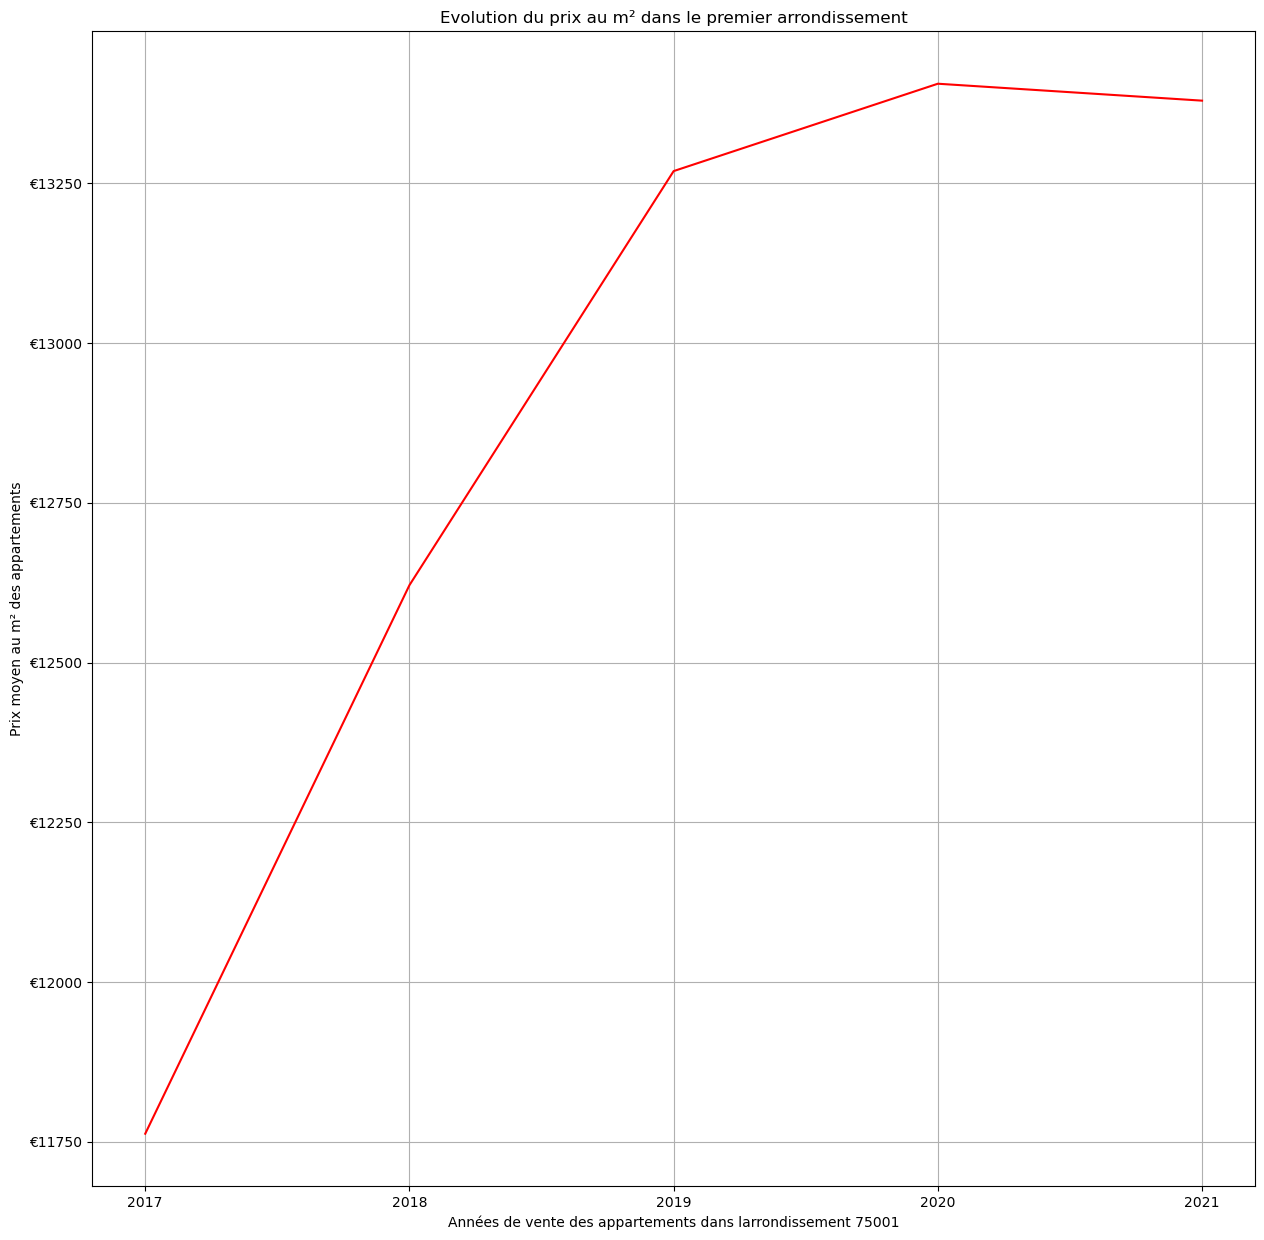

In [50]:
#Création d'un graphique pour visualiser la hausse de la moyenne des prix au metre carré dans le premier arrondissement
plt.figure(figsize=(15,15))
plt.plot(['2017','2018','2019','2020','2021'], df_cp.loc[75001], color='red')
plt.xlabel('Années de vente des appartements dans larrondissement 75001')
plt.ylabel('Prix moyen au m² des appartements')
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)
plt.grid()
plt.title('Evolution du prix au m² dans le premier arrondissement')
plt.show()

Nous allons ajouter à cette visualisation tous les autres arrondissement avec une couleur différente.

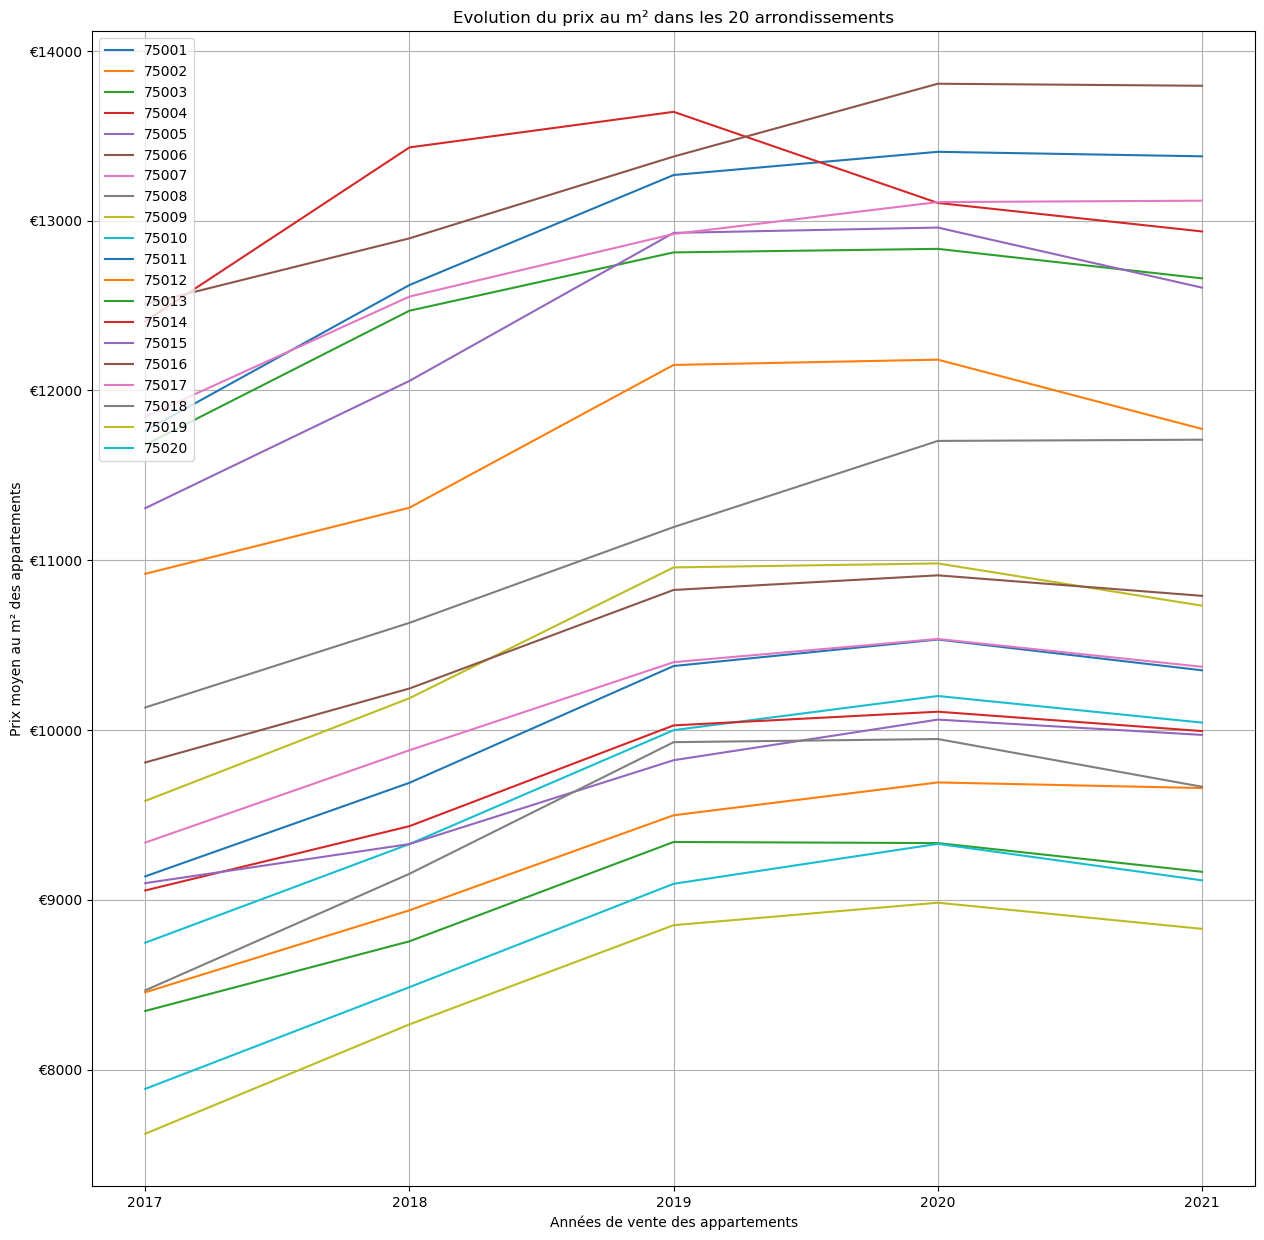

In [51]:
#On affiche l'évolution du prix au m² par arrondissement dans Paris
plt.figure(figsize=(15,15))
interval_historique=['2017','2018','2019','2020','2021']
#Insérer les lignes à tracer ci-dessous
for cp in df_cp.index:
    plt.plot(interval_historique, df_cp.loc[cp], label=str(cp))

plt.xlabel('Années de vente des appartements')
plt.ylabel('Prix moyen au m² des appartements')
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)
plt.grid()
plt.title('Evolution du prix au m² dans les 20 arrondissements')
plt.legend(loc='upper left')
plt.show()

On observe globalement que **tous les arrondissements suivent la même tendance** (hausse de 2017 à 2019-2020, puis stabilisation ou légère baisse en 2021), mais avec des **niveaux de prix très différents** : les arrondissements du centre et de la rive gauche (1er, 4e, 6e, 7e) dépassent 13 000 €/m², alors que le nord-est (19e, 20e) reste autour de 9 000 €/m². L'écart entre le plus cher et le moins cher est d'environ **5 000 €/m²** : la **localisation** est donc une variable clé pour prédire le prix.

### 7. Prix au metre carré par transaction dans un arrondissement

In [52]:
#Vérifions le nombre de transaction dans le 6ème car le prix semble élevé
df_6 = df_appart[df_appart['code_postal'] == 75006]
print('Nombre de transactions dans le 6e :', len(df_6))
df_6['prix_m2'].describe().round(2)

Nombre de transactions dans le 6e : 709


count      709.00
mean     13143.51
std        565.78
min      12065.24
25%      12647.67
50%      13122.73
75%      13631.59
max      14169.82
Name: prix_m2, dtype: float64

On constate que **le 6e compte 709 ventes d'appartements**, ce qui est suffisant pour que la moyenne soit fiable. Le prix au m² y varie de 12 065 € à 14 170 € avec un écart-type d'environ 566 € : les prix sont élevés mais **assez homogènes**.

Affichons l'historique des transactions pour visualiser la dispersion des données :

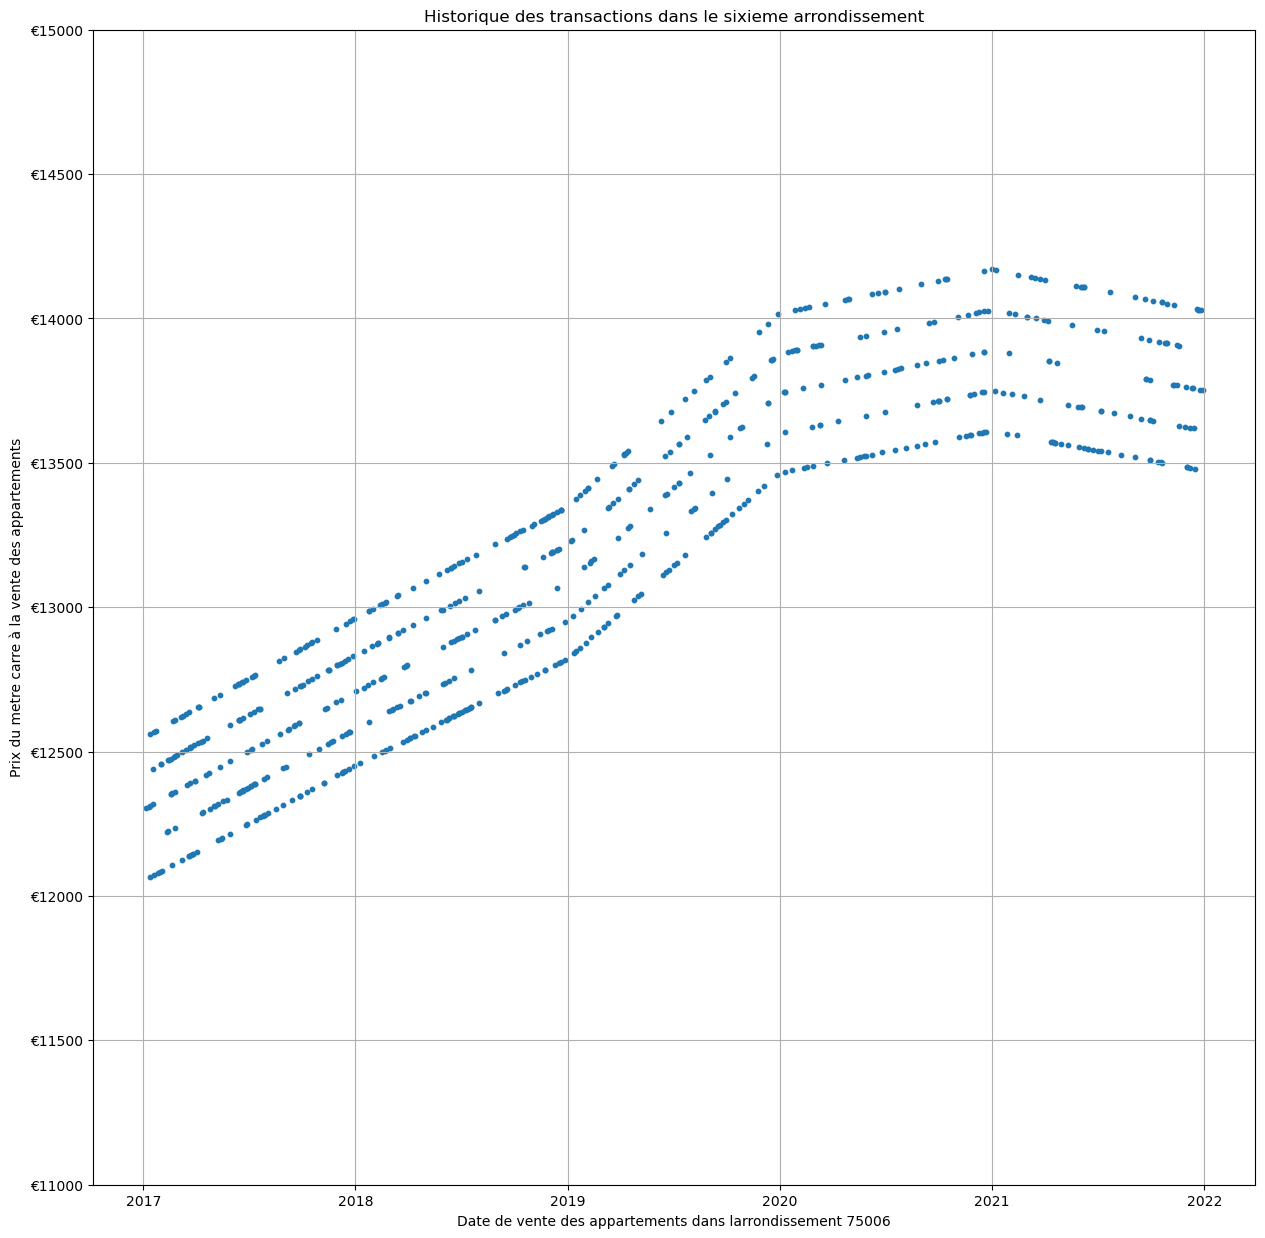

In [53]:
cp=75006
plt.figure(figsize=(15,15))
#Insérer ci-dessous le scatter plot
df_cp6 = df_appart[df_appart['code_postal'] == cp]
plt.scatter(df_cp6['date_mutation'], df_cp6['prix_m2'], s=10)

plt.xlabel('Date de vente des appartements dans larrondissement 75006')
plt.ylabel('Prix du metre carre à la vente des appartements')
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)
plt.ylim(11000,15000)
plt.grid(which='both')
plt.title('Historique des transactions dans le sixieme arrondissement')
plt.show()

On observe que **les points forment une bande qui monte avec le temps** : plus la vente est récente, plus le prix au m² est élevé, de 2017 à fin 2020. En 2021 la tendance s'inverse légèrement (petite baisse). La relation est donc globalement croissante et presque linéaire sur la période.

Pour nous rassurer sur la relation entre les données nous allons utiliser un test statistique de corrélation.

### 8. Vérification de la relation entre le prix au m² et la date dans le 6ème arrondissement par le calcul du coefficient de corrélation de Pearson 

Pour cette distribution nous allons calculer le coefficient de corrélation de Pearson. La relation entre le prix au metre carré et la date n'est pas forcément linéaire mais elle s'en rapproche suffisamment pour que cette analyse soit pertinente (voir l'évolution du prix au metre carré globale montrée plus haut, on a presque une droite sauf entre 2020 et 2021). Ce qui nous interesse c'est de prouver que le temps a une influence sur le prix.

- proche de **+1** : quand l'une monte, l'autre monte ;
- proche de **0** : pas de relation linéaire ;
- proche de **-1** : quand l'une monte, l'autre descend.

La **p-value** indique la probabilité d'observer une telle corrélation **par hasard**. Si elle est **inférieure à 0,05**, on considère la corrélation comme **statistiquement significative**.

Pearson n'accepte que des nombres : on convertit donc la date en nombre avec `.astype('int64')` (nombre de microsecondes depuis 1970 ; peu importe l'unité, seul l'ordre compte). *Remarque : le commentaire du modèle dit « Spearman » mais la consigne demande bien Pearson, c'est `stats.pearsonr` qu'on utilise.*

In [54]:
#On calcule la corrélation de Pearson
from scipy import stats
r, pvalue = stats.pearsonr(df_cp6['date_mutation'].astype('int64'), df_cp6['prix_m2'])
print(f'coefficient de corrélation : {r:.2f}')
print('p-value :', pvalue)

coefficient de corrélation : 0.90
p-value : 7.108378962577143e-263


Le coefficient de corrélation est de **0,90** avec une pvalue de **7,1 × 10⁻²⁶³** (pratiquement 0, bien inférieure à 0,05) donc nous pouvons confirmer la corrélation : **la date a une forte influence positive sur le prix au m²**.

### 9. Vérification de la relation entre la valeur fonciere et la surface

coefficient de corrélation : 0.98
p-value : 0.0


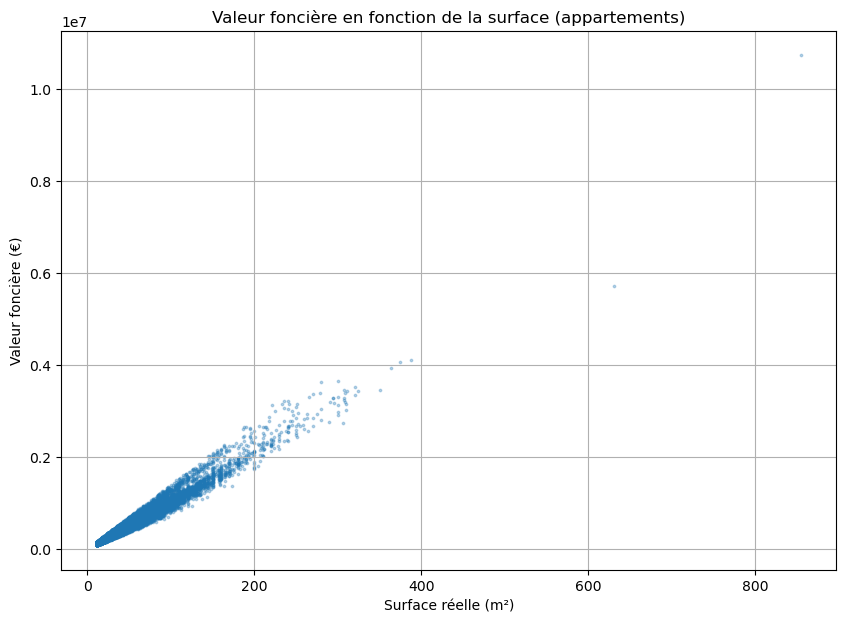

In [55]:
# Corrélation entre la surface et la valeur foncière (tous arrondissements, appartements)
r, pvalue = stats.pearsonr(df_appart['surface_reelle'], df_appart['valeur_fonciere'])
print(f'coefficient de corrélation : {r:.2f}')
print('p-value :', pvalue)

plt.figure(figsize=(10,7))
plt.scatter(df_appart['surface_reelle'], df_appart['valeur_fonciere'], s=3, alpha=0.3)
plt.xlabel('Surface réelle (m²)')
plt.ylabel('Valeur foncière (€)')
plt.title('Valeur foncière en fonction de la surface (appartements)')
plt.grid()
plt.show()

Le coefficient de corrélation est de **0,98** avec une pvalue de **0** (trop petite pour être affichée). La relation est donc confirmée : **plus le bien est grand, plus il est cher**, de façon quasi linéaire. La surface est la variable la plus déterminante pour prédire la valeur foncière.

Regardons maintenant si le type de bien à une influence sur le prix au metre carré également.

### 10. Analyse des locaux industriels, commerciaux et assimilés 

In [56]:
#On crée un dataset qui ne contient que les locaux commerciaux
df_local = df[df['code_type_local'] == 4].drop(columns=['adresse_numero','adresse_nom_voie','nom_commune','type_local'])
df_local.head()

,date_mutation,valeur_fonciere,code_postal,code_type_local,surface_reelle,prix_m2,annee
18,2017-02-01,3.113277e+06,75003,4,250,12453.109192,2017
29,2017-02-17,1.164375e+06,75003,4,95,12256.581685,2017
34,2017-02-20,3.802522e+05,75003,4,31,12266.199603,2017
91,2017-03-09,3.623842e+05,75001,4,29,12496.006027,2017
109,2017-03-29,3.159072e+05,75003,4,25,12636.289027,2017


In [57]:
#Préparons un dataframe en regroupant les prix au metre carré moyens des ventes par année
df_local_annee = df_local.groupby('annee')['prix_m2'].mean().round(2)

# Tableau comparatif
pd.DataFrame({'locaux commerciaux': df_local_annee, 'appartements': df_annee.set_index('annee')['prix_m2']})

,locaux commerciaux,appartements
annee,,
2017,10949.91,9492.86
2018,11569.50,10031.40
2019,11960.13,10562.71
2020,11966.47,10674.87
2021,12006.49,10455.60


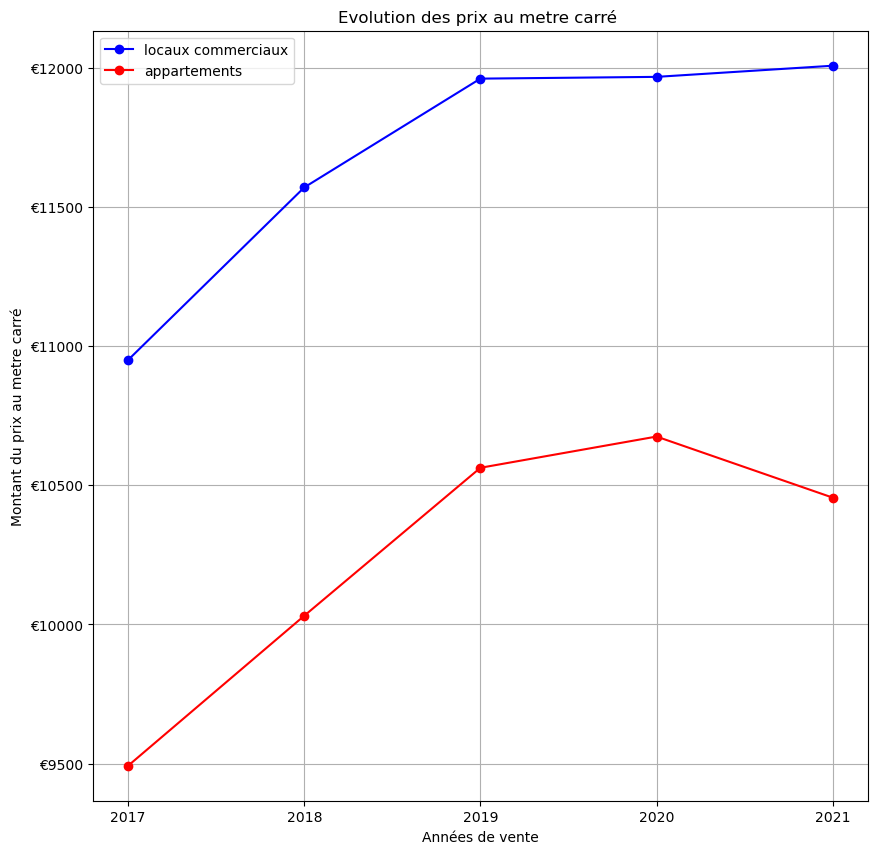

In [58]:
#Création d'un graphique pour visualiser la hausse de la moyenne des prix
plt.figure(figsize=(10,10))
plt.plot(['2017','2018','2019','2020','2021'], df_local_annee, label='locaux commerciaux', color='blue', marker='o')
plt.plot(['2017','2018','2019','2020','2021'], df_annee['prix_m2'], label='appartements', color='red', marker='o')
plt.xlabel('Années de vente')
plt.ylabel('Montant du prix au metre carré')
plt.legend()
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)
plt.grid()
plt.title('Evolution des prix au metre carré ')
plt.show()

Le prix au metre carré des locaux commerciaux est **systématiquement plus élevé que celui des appartements**, d'environ **1 500 €/m²** (12 006 € contre 10 456 € en 2021). Les deux courbes ont la même tendance (hausse puis plateau), mais les locaux ne baissent pas en 2021. Le **type de bien** influence donc lui aussi le prix au m².

Après ces analyses, nous pouvons conclure que les dimensions à utiliser pour prédire le prix au m² sont : 
- la surface du bien immobilier,
- la date considérée, 
- la localisation (code_postal), 
- le type de bien.

# Milestone 2 - Entraînement de l'algorithme

Dans cette section nous allons maintenant entrâiner un algorithme à prédire la valeur fonciere d'un bien immobilier. Pour cela nous allons utiliser l'algorithme de régression linéaire.

La **régression linéaire** fabrique une règle de la forme :

`prix = a × surface + b × date + c(arrondissement) + d(type de bien) + constante`

Son travail consiste à trouver les meilleurs nombres `a`, `b`, `c`, `d` : ceux qui font le moins d'erreurs sur les ventes passées.

On commence par préparer nos données en transformant les colonnes catégoriques du code postal et du type de local grâce au one hot encoder (sklearn) / get_dummies (pandas)

**1. Choisir les colonnes.** On garde uniquement les 4 dimensions identifiées au Milestone 1 (surface, date, code postal, type de bien) et la cible (`valeur_fonciere`). ⚠️ On **ne garde surtout pas** `prix_m2` : il a été calculé *à partir* de la valeur foncière. Le donner à l'algorithme, ce serait lui donner la réponse dans l'énoncé (on appelle ça une **fuite de données**, *data leakage*). Son score serait excellent… et totalement faux.

**2. Transformer la date en nombre.** On calcule le **nombre de jours écoulés depuis le 1er janvier 2017** (`.dt.days`). Le 2 janvier 2017 devient 1, le 31 décembre 2021 devient 1825. Ainsi « plus tard » = « plus grand nombre », et l'algorithme peut capter la hausse des prix dans le temps.

**3. Le *one hot encoding* avec `pd.get_dummies()`.** Le code postal 75020 n'est pas « plus grand » que 75001 au sens du prix : c'est une **catégorie**, pas une quantité. Si on le laissait tel quel, l'algorithme croirait que le prix augmente avec le numéro de l'arrondissement ! `get_dummies` crée donc **une colonne par arrondissement** (`code_postal_75001`, `code_postal_75002`…) qui vaut **1** si le bien est dans cet arrondissement et **0** sinon. Même chose pour le type de bien. `dtype=int` demande des 0/1 plutôt que des True/False.

In [59]:
# 1. On repart du dataframe complet (appartements + locaux) et on garde les colonnes utiles
df_ml = df[['date_mutation', 'surface_reelle', 'code_postal', 'type_local', 'valeur_fonciere']].copy()

# 2. On transforme la date en nombre de jours écoulés depuis le 1er janvier 2017
date_reference = pd.Timestamp('2017-01-01')
df_ml['jours'] = (df_ml['date_mutation'] - date_reference).dt.days
df_ml = df_ml.drop(columns='date_mutation')

# 3. One hot encoding des variables catégorielles
df_ml = pd.get_dummies(df_ml, columns=['code_postal', 'type_local'], dtype=int)

print('Dimensions du tableau :', df_ml.shape)
df_ml.head()

Dimensions du tableau : (26196, 25)


,surface_reelle,valeur_fonciere,jours,code_postal_75001,code_postal_75002,code_postal_75003,code_postal_75004,code_postal_75005,code_postal_75006,code_postal_75007,...,code_postal_75013,code_postal_75014,code_postal_75015,code_postal_75016,code_postal_75017,code_postal_75018,code_postal_75019,code_postal_75020,type_local_Appartement,type_local_Local industriel. commercial ou assimilé
0,50,5.505597e+05,2,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,163,1.576492e+06,11,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,66,6.577574e+05,9,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,22,2.500868e+05,9,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,15,1.762667e+05,12,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


On passe de 5 colonnes à **25** : la surface, les jours, la valeur foncière, 20 colonnes d'arrondissement et 2 colonnes de type de bien. Sur chaque ligne, une seule colonne d'arrondissement vaut 1, toutes les autres valent 0.

On utilise le train_test_split pour prélever un tiers de nos données (33%) et les garder de côté. Nous allons entraîner notre algorithme sur le reste des données et puis mesurer notre erreur moyenne en pourcentage de la valeur foncière

- `X` = les **variables explicatives** (tout sauf le prix) ; `y` = la **cible** à prédire (la valeur foncière).
- `train_test_split` **mélange les ventes au hasard**, puis les répartit en 4 morceaux : `X_train`/`y_train` pour apprendre, `X_test`/`y_test` pour évaluer.
- `random_state=6` fixe le tirage au sort : on obtient exactement le même découpage à chaque exécution (numéro demandé par le mentor, pour que les résultats soient reproductibles et comparables).

*Le point de vigilance de l'énoncé sur la chronologie (apprendre sur le passé, tester sur le futur) est étudié plus bas, dans l'analyse critique.*

In [60]:
# On sépare le jeu de données entre echantillons d'apprentissage et de test 
# La valeur y à trouver est la valeur foncière
from sklearn.model_selection import train_test_split

X = df_ml.drop(columns='valeur_fonciere')
y = df_ml['valeur_fonciere']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=6)

print('Ventes pour l\'apprentissage :', len(X_train))
print('Ventes pour le test :', len(X_test))

Ventes pour l'apprentissage : 17551
Ventes pour le test : 8645


In [61]:
#conversion des données en str
X_train.columns = X_train.columns.astype(str)
X_test.columns = X_test.columns.astype(str)

1. `modele = LinearRegression()` : on crée un modèle vide.
2. `modele.fit(X_train, y_train)` : il **apprend** (*fit* = « ajuster ») sur les ventes d'entraînement.
3. `modele.predict(X_test)` : il **prédit** le prix des ventes de test, qu'il n'a jamais vues.

Pour mesurer l'erreur, on calcule pour chaque vente l'**écart en pourcentage** entre le prix prédit et le vrai prix : `|prédit − réel| / réel`. Puis on fait la moyenne. C'est le **MAPE** (*Mean Absolute Percentage Error*, erreur absolue moyenne en pourcentage). La valeur absolue `abs()` évite qu'une erreur de +10 % et une de −10 % s'annulent.

In [62]:
from sklearn.linear_model import LinearRegression
#On entraîne l'algorithme ci-dessous et on effectue la prédiction

modele = LinearRegression()
modele.fit(X_train, y_train)

y_pred = modele.predict(X_test)

# Erreur moyenne en pourcentage de la valeur foncière (MAPE)
erreur = (abs(y_pred - y_test) / y_test).mean() * 100
print('Erreur moyenne de prédiction :', round(erreur, 2), '%')

Erreur moyenne de prédiction : 8.93 %


In [63]:
comparaison = pd.DataFrame({
    'surface': X_test['surface_reelle'],
    'prix réel': y_test.round(2),
    'prix prédit': y_pred.round(2),
})
comparaison['écart (%)'] = ((comparaison['prix prédit'] - comparaison['prix réel']) / comparaison['prix réel'] * 100).round(2)
comparaison.head(10)

,surface,prix réel,prix prédit,écart (%)
18752,40,411591.68,392211.58,-4.71
11722,32,417960.17,473265.04,13.23
5496,61,766709.33,740301.07,-3.44
17494,15,154921.85,133939.47,-13.54
7972,53,488661.45,503904.49,3.12
7602,62,619567.04,619784.15,0.04
4179,12,113397.19,86044.19,-24.12
22558,25,261059.76,276428.02,5.89
21922,32,321685.19,326297.81,1.43
24108,16,163949.34,179382.50,9.41


In [64]:
coefficients = pd.Series(modele.coef_, index=X_train.columns).round(2)
coefficients

surface_reelle                                          10414.18
jours                                                      39.68
code_postal_75001                                      101405.38
code_postal_75002                                       36648.92
code_postal_75003                                       71488.96
code_postal_75004                                      109417.99
code_postal_75005                                       50137.90
code_postal_75006                                      138497.53
code_postal_75007                                      118321.87
code_postal_75008                                       41835.63
code_postal_75009                                      -19043.88
code_postal_75010                                      -56462.58
code_postal_75011                                      -38616.13
code_postal_75012                                      -72077.97
code_postal_75013                                      -76783.79
code_postal_75014        

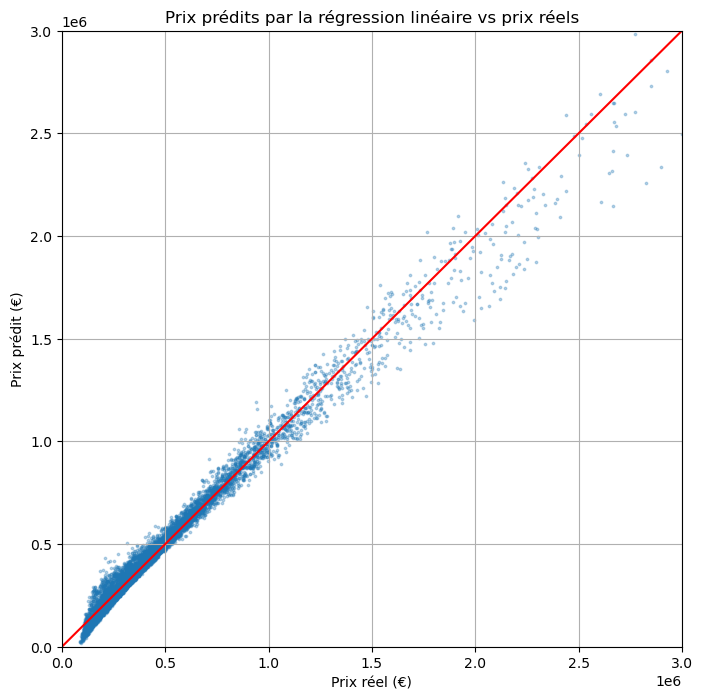

In [65]:
plt.figure(figsize=(8,8))
plt.scatter(y_test, y_pred, s=3, alpha=0.3)
plt.plot([0, 3_000_000], [0, 3_000_000], color='red')
plt.xlim(0, 3_000_000)
plt.ylim(0, 3_000_000)
plt.xlabel('Prix réel (€)')
plt.ylabel('Prix prédit (€)')
plt.title('Prix prédits par la régression linéaire vs prix réels')
plt.grid()
plt.show()

In [66]:
# Écart moyen AVEC le signe : positif = le modèle surestime en moyenne
biais = ((y_pred - y_test) / y_test).mean() * 100
print('Écart moyen avec le signe :', round(biais, 2), '%')

Écart moyen avec le signe : 0.07 %


L'écart moyen avec le signe est quasiment nul (**+0,07 %**) : le modèle se trompe **autant vers le haut que vers le bas**. Il n'est pas biaisé en moyenne, ce qui est rassurant pour une valorisation globale de portefeuille.

### Analyse critique : séparation manuelle et chronologique (point de vigilance de l'énoncé)

In [67]:
# Séparation manuelle et chronologique
df_chrono = df_ml.sort_values('jours', kind='stable')
Xc = df_chrono.drop(columns='valeur_fonciere')
yc = df_chrono['valeur_fonciere']

limite = int(len(Xc) * 0.67)
Xc_train, yc_train = Xc.iloc[:limite], yc.iloc[:limite]
Xc_test, yc_test = Xc.iloc[limite:], yc.iloc[limite:]
print('Apprentissage : jours', Xc_train['jours'].min(), 'à', Xc_train['jours'].max(), '- Test : jours', Xc_test['jours'].min(), 'à', Xc_test['jours'].max())

modele_chrono = LinearRegression().fit(Xc_train, yc_train)
pred_chrono = modele_chrono.predict(Xc_test)
erreur_chrono = (abs(pred_chrono - yc_test) / yc_test).mean() * 100
biais_chrono = ((pred_chrono - yc_test) / yc_test).mean() * 100

print('Erreur - séparation au hasard (random_state=6) :', round(erreur, 2), '%')
print('Erreur - séparation chronologique :', round(erreur_chrono, 2), '%')
print('Écart moyen avec le signe (chronologique) :', round(biais_chrono, 2), '%')

Apprentissage : jours 1 à 1157 - Test : jours 1157 à 1825
Erreur - séparation au hasard (random_state=6) : 8.93 %
Erreur - séparation chronologique : 16.72 %
Écart moyen avec le signe (chronologique) : 15.84 %


Testé dans l'ordre du temps (apprentissage de janvier 2017 à mars 2020, test de mars 2020 à décembre 2021), le même modèle fait **16,72 %** d'erreur et **surestime** les prix de **+15,84 %** en moyenne. Il a appris pendant une période de **forte hausse** et la prolonge **en ligne droite**, alors que le marché s'est **stabilisé puis a légèrement baissé** en 2021. Cette analyse montre la principale limite de la régression linéaire : elle **ne sait pas anticiper un retournement de tendance**. Elle invite à la prudence pour le Milestone 3, où l'on prédit **2022**, une année absente des données : les valorisations seront probablement **un peu optimistes**.

Notre algorithme fait donc **8,93 %** d'erreur en moyenne sur la prédiction de la valeur foncière.

Mes conclusions sur ce résultat et comment j'aurais pu aller plus loin :
- **L'objectif de moins de 10 % est atteint** avec la séparation au hasard (`random_state=6`), et le modèle n'est pas biaisé en moyenne (+0,07 %).
- **Avis critique sur la régression linéaire dans notre contexte** : testée dans l'ordre du temps, elle fait **16,72 %** d'erreur, car elle prolonge en ligne droite la hausse apprise et **surestime** les prix quand le marché se stabilise. De plus, elle **additionne** les effets : elle ajoute un même montant fixe pour « être dans le 6e », que le bien fasse 15 m² ou 150 m², alors que l'arrondissement agit en réalité sur le **prix au m²**.
- **Pour réduire l'erreur** : prédire le prix au m² puis le multiplier par la surface (voir ci-dessous). On pourrait aussi tester d'autres algorithmes non linéaires (arbre de décision, forêt aléatoire), utiliser une validation chronologique sur plusieurs périodes, ajouter des variables (étage, état du bien, nombre de pièces…) ou des indicateurs de marché (taux d'intérêt), et ré-entraîner régulièrement le modèle avec les ventes les plus récentes.

### Bonus (pour aller plus loin) : prédire le prix au m² plutôt que le prix total

In [68]:
# Cible = prix au m² (calculé uniquement sur le jeu d'entraînement)
y_train_m2 = y_train / X_train['surface_reelle']

modele_m2 = LinearRegression()
modele_m2.fit(X_train, y_train_m2)

# Prédiction du prix au m², puis multiplication par la surface pour obtenir le prix total
y_pred_m2 = modele_m2.predict(X_test) * X_test['surface_reelle']

erreur_m2 = (abs(y_pred_m2 - y_test) / y_test).mean() * 100
print('Erreur moyenne en prédisant le prix au m² :', round(erreur_m2, 2), '%')

Erreur moyenne en prédisant le prix au m² : 2.61 %


L'erreur chute à **2,61 %**. Même algorithme, mêmes données, même séparation : seule la façon de poser le problème a changé. Le gain se confirme dans l'ordre du temps : avec la séparation chronologique, ce modèle ferait **8,47 %**, contre 16,72 % pour le modèle de base. C'est la réponse à la question « comment aller plus loin pour réduire le taux d'erreur ».

# Milestone 3 - Prédiction définitive pour le client 

Nous avons récupéré le fichier avec le portefeuille des actifs de la société. Nous allons l'importer puis effectuer la prédiction et statuer sur la branche qui, selon notre prédiction, aura le plus de valeur à la date demandée c'est à dire au 31 décembre 2022.<br>
Petite précision, nous souhaitons continuer à utiliser la surface réelle pour faire les calculs et pas la surface carrez. 

In [73]:
#On importe les données dans un dataframe
portefeuille = pd.read_excel('portefeuille_actifs+(3).xlsx')
print('Nombre de biens dans le portefeuille :', len(portefeuille))
print(portefeuille['type_local'].value_counts())
portefeuille.head()

Nombre de biens dans le portefeuille : 275
type_local
Appartement                                 154
Local industriel. commercial ou assimilé    121
Name: count, dtype: int64


,adresse_numero,adresse_nom_voie,code_postal,code_commune,nom_commune,surface_carrez,code_type_local,type_local,surface_reelle_bati,nombre_pieces_principales,longitude,latitude
0,127,RUE SAINT-DENIS,75001,75101,Paris 1er Arrondissement,16.41,2,Appartement,25,1,2.349593,48.863227
1,62,RUE NOTRE-DAME DE NAZARETH,75003,75103,Paris 3e Arrondissement,20.47,2,Appartement,22,1,2.356977,48.867907
2,62,RUE DE TURENNE,75003,75103,Paris 3e Arrondissement,64.48,2,Appartement,65,3,2.364855,48.859318
3,32,AV GEORGE V,75008,75108,Paris 8e Arrondissement,63.29,2,Appartement,74,2,2.301586,48.868893
4,152,BD HAUSSMANN,75008,75108,Paris 8e Arrondissement,20.58,2,Appartement,22,1,2.311643,48.875490


Nous avons la liste des biens immobiliers de l'entreprise. Pour effectuer une prédiction, nous devons mettre ce fichier au même format que le dataframe que nous avons utilisé lors de l'entraînement de l'algorithme.

1. On garde la **surface réelle** (et pas la surface Carrez, comme demandé) et on la **renomme** `surface_reelle` avec `.rename()`, pour qu'elle porte le même nom qu'à l'entraînement.
2. On crée la colonne `jours` avec la **date de la prédiction** : le 31 décembre 2022. On calcule le nombre de jours depuis la **même date de référence** qu'à l'entraînement (1er janvier 2017). C'est la même valeur pour tous les biens, puisqu'on veut leur prix à cette date-là.
3. On refait le **one hot encoding** avec `get_dummies`.
4. On utilise `.reindex(columns=X_train.columns, fill_value=0)` : cette ligne **remet les colonnes dans le même ordre** qu'à l'entraînement et **crée à 0** celles qui manqueraient (par exemple si aucun bien du portefeuille n'était situé dans le 2e, la colonne `code_postal_75002` n'existerait pas). C'est une sécurité très importante.

In [74]:
#On réutilise les mêmes fonctions pour faire le one hot encoding des variables catégorielles

#On importe la librairie datetime pour pouvoir créer une colonne timestamp avec la date du 31 décembre 2022 pour la prédiction
import datetime as dt

# 1. On garde les colonnes utiles et on renomme la surface réelle comme à l'entraînement
df_pred = portefeuille[['surface_reelle_bati', 'code_postal', 'type_local']].rename(columns={'surface_reelle_bati': 'surface_reelle'})

# 2. Date de prédiction : 31 décembre 2022, en nombre de jours depuis le 1er janvier 2017 (même référence qu'à l'entraînement)
date_prediction = pd.Timestamp(dt.date(2022, 12, 31))
df_pred['jours'] = (date_prediction - date_reference).days
print('Nombre de jours entre le 01/01/2017 et le 31/12/2022 :', df_pred['jours'].iloc[0])

# 3. One hot encoding
df_pred = pd.get_dummies(df_pred, columns=['code_postal', 'type_local'], dtype=int)

# 4. Mêmes colonnes, dans le même ordre qu'à l'entraînement (colonnes manquantes créées à 0)
df_pred = df_pred.reindex(columns=X_train.columns, fill_value=0)
df_pred.head()

Nombre de jours entre le 01/01/2017 et le 31/12/2022 : 2190


,surface_reelle,jours,code_postal_75001,code_postal_75002,code_postal_75003,code_postal_75004,code_postal_75005,code_postal_75006,code_postal_75007,code_postal_75008,...,code_postal_75013,code_postal_75014,code_postal_75015,code_postal_75016,code_postal_75017,code_postal_75018,code_postal_75019,code_postal_75020,type_local_Appartement,type_local_Local industriel. commercial ou assimilé
0,25,2190,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,22,2190,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,65,2190,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,74,2190,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
4,22,2190,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0


In [75]:
#Conversion du dataframe en str
df_pred.columns = df_pred.columns.astype(str)

Notre dataframe est prêt à être utilisé par notre algorithme de prédiction.

In [76]:
#On effectue la prédiction
portefeuille['valeur_predite'] = modele.predict(df_pred).round(2)

#On vérifie les 10 premières valeurs
portefeuille[['adresse_numero', 'adresse_nom_voie', 'code_postal', 'type_local', 'surface_reelle_bati', 'valeur_predite']].head(10)

,adresse_numero,adresse_nom_voie,code_postal,type_local,surface_reelle_bati,valeur_predite
0,127,RUE SAINT-DENIS,75001,Appartement,25,433567.93
1,62,RUE NOTRE-DAME DE NAZARETH,75003,Appartement,22,372408.98
2,62,RUE DE TURENNE,75003,Appartement,65,820218.57
3,32,AV GEORGE V,75008,Appartement,74,884292.83
4,152,BD HAUSSMANN,75008,Appartement,22,342755.65
5,152,BD HAUSSMANN,75008,Appartement,35,478139.94
6,52,RUE DES GRAVILLIERS,75003,Appartement,24,393237.33
7,208,RUE SAINT MAUR,75010,Appartement,60,640196.15
8,142,RUE DE COURCELLES,75017,Appartement,11,149121.45
9,52,RUE LAMARCK,75018,Appartement,13,147768.51


Maintenant nous allons comparer la valorisation prédite pour les deux segments.

- le **segment particulier** : les **appartements**, destinés à des particuliers (code type 2) ;
- le **segment corporate** : les **locaux industriels et commerciaux**, destinés à des entreprises (code type 4).

La valorisation d'un segment, c'est la **somme** des valeurs prédites de tous ses biens. On filtre chaque segment, puis on additionne avec `.sum()`. On divise par 1 000 000 pour afficher le résultat en millions d'euros, plus lisible.

In [77]:
# On sépare les deux segments
segment_particulier = portefeuille[portefeuille['code_type_local'] == 2]
segment_corporate = portefeuille[portefeuille['code_type_local'] == 4]
print('Nombre de biens - segment particulier :', len(segment_particulier))
print('Nombre de biens - segment corporate :', len(segment_corporate))

Nombre de biens - segment particulier : 154
Nombre de biens - segment corporate : 121


In [78]:
#Valorisation du portefeuille sur le segment des particuliers
valo_particulier = segment_particulier['valeur_predite'].sum() / 1_000_000
print('la valorisation du segment particulier est (en millions deuros):', round(valo_particulier, 2))

la valorisation du segment particulier est (en millions deuros): 71.24


In [79]:
#Valorisation du portefeuille sur le segment corporate
valo_corporate = segment_corporate['valeur_predite'].sum() / 1_000_000
print('la valorisation du segment corporate est (en millions deuros):', round(valo_corporate, 2))

la valorisation du segment corporate est (en millions deuros): 98.32


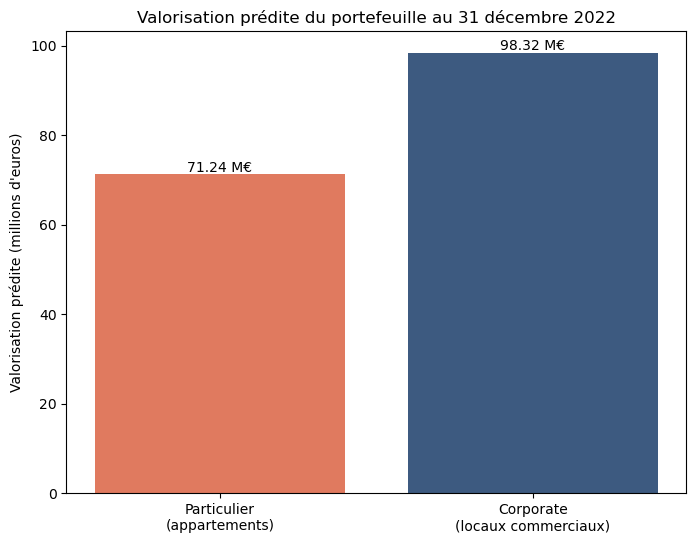

In [80]:
plt.figure(figsize=(8,6))
barres = plt.bar(['Particulier\n(appartements)', 'Corporate\n(locaux commerciaux)'], [valo_particulier, valo_corporate], color=['#E07A5F', '#3D5A80'])
plt.bar_label(barres, fmt='%.2f M€')
plt.ylabel('Valorisation prédite (millions d\'euros)')
plt.title('Valorisation prédite du portefeuille au 31 décembre 2022')
plt.show()

In [81]:
portefeuille['valeur_predite_m2'] = (modele_m2.predict(df_pred) * df_pred['surface_reelle']).round(2)
verif = portefeuille.groupby('type_local')[['valeur_predite', 'valeur_predite_m2']].sum() / 1_000_000
verif.columns = ['Modèle principal (M€)', 'Modèle prix au m² (M€)']
verif.round(2)

,Modèle principal (M€),Modèle prix au m² (M€)
type_local,,
Appartement,71.24,69.42
Local industriel. commercial ou assimilé,98.32,97.30


Mes conclusions sur le segment avec la plus grande valorisation et sur les limites de cette estimation :
- **Le segment corporate aura la plus grande valorisation au 31 décembre 2022 : 98,32 M€, contre 71,24 M€ pour le segment particulier**, soit un total de 169,56 M€. Le modèle « prix au m² » (2,61 % d'erreur) confirme ce classement : **97,30 M€** pour le corporate et **69,42 M€** pour le particulier (166,72 M€ au total). Le corporate pèse plus lourd alors qu'il compte **moins de biens** (121 contre 154) : les locaux sont en moyenne plus grands et leur prix au m² est plus élevé. La conclusion est donc **robuste**.
- **Limites** : ces montants sont des **ordres de grandeur**. On prédit **fin 2022 alors que les données s'arrêtent fin 2021**, et le modèle prolonge la hausse qu'il a apprise (environ 40 € par jour). Or l'analyse chronologique du Milestone 2 a montré qu'une régression linéaire testée sur le futur **surestime** les prix d'environ 16 % quand le marché se stabilise, ce qui a été le cas en 2021. Les valorisations sont donc probablement **surestimées**. Enfin, le modèle a appris sur seulement 7 % de locaux commerciaux, il est donc un peu moins fiable sur le segment corporate.

# Milestone 4 - Classification des données issues du jeu de test

Dans cette partie nous allons labelliser automatiquement les biens immobiliers comme étant :
- soit des Appartements
- soit des Local industriel. commercial ou assimilé
Pour cela nous allons utiliser l'algorithme du KMeans sur le jeu de données partagé par l'entreprise.

Pour que l'algorithme fonctionne, il faut que nous préparions les données en supprimant les dimensions inutiles et en nous concentrant sur le facteur discriminant entre les appartements et les locaux commerciaux : la différence dans le prix au mètre carré tel que nous l'avons vu avant.

Le fichier `echantillon_a_classer2.xlsx` contient **40 ventes** du **19e arrondissement**, avec leur valeur foncière et leur surface, mais **sans le type de bien** : c'est ce que nous allons retrouver.

In [82]:
#On importe les données dans un dataframe
fichier_a_classer = 'echantillon_a_classer2.xlsx'
df_classif = pd.read_excel(fichier_a_classer)
print('Nombre de ventes à classer :', len(df_classif))
df_classif.head()

Nombre de ventes à classer : 40


,valeur_fonciere,code_postal,nom_commune,surface_reelle
0,868687.083271,75019,Paris 19e Arrondissement,88
1,452050.762192,75019,Paris 19e Arrondissement,45
2,193088.653587,75019,Paris 19e Arrondissement,21
3,303012.549370,75019,Paris 19e Arrondissement,32
4,149272.200110,75019,Paris 19e Arrondissement,20


On applique les transformations nécessaires. Tout d'abord nous allons calculer le prix au mètre carré en divisant la valeur foncière par la surface. Ensuite nous allons retirer ces colonnes car nous avons déjà l'information qu'elles contiennent dans la dimension prix au mètre carré désormais.

Enfin toutes nos données sont de l'année 2021. Nous allons retirer cette dimension qui ne devrait pas être discriminante dans le regroupement des données.

In [83]:
df_classif['prix_m2'] = df_classif['valeur_fonciere'] / df_classif['surface_reelle']
df_kmeans = df_classif.drop(columns=['valeur_fonciere', 'surface_reelle', 'date_mutation'], errors='ignore')
print('Arrondissements présents :', df_kmeans['code_postal'].unique())
df_kmeans.head()

Arrondissements présents : [75019]


,code_postal,nom_commune,prix_m2
0,75019,Paris 19e Arrondissement,9871.444128
1,75019,Paris 19e Arrondissement,10045.572493
2,75019,Paris 19e Arrondissement,9194.697790
3,75019,Paris 19e Arrondissement,9469.142168
4,75019,Paris 19e Arrondissement,7463.610005


Nous observons dans les données que nous avons des valeurs différentes de prix au mètre carré pour un même arrondissement (ici le 19ème arrondissement). Il se peut fort que cela soit notre dimension à utiliser pour attribuer les prix au mètre carré les plus élévé dans un département aux locaux commerciaux, et les prix les plus bas aux appartements.

Pour effectuer cette opération, nous allons utiliser l'algorithme du Kmeans qui va rechercher 2 centroïdes à travers les données.

1. il place **2 points au hasard** sur l'axe des prix au m² : ce sont les **centroïdes** (les « centres » des groupes) ;
2. il rattache chaque vente au centroïde **le plus proche** ;
3. il déplace chaque centroïde **au milieu** de son groupe (la moyenne des prix au m² du groupe) ;
4. il recommence les étapes 2 et 3 jusqu'à ce que plus rien ne bouge.

On lui donne **uniquement la colonne `prix_m2`** : c'est le facteur qui distingue appartements et locaux (on a vu au Milestone 1 que les locaux sont environ 1 500 €/m² plus chers). `random_state=0` fixe le hasard du point de départ, et `n_init=10` relance l'algorithme 10 fois pour garder le meilleur résultat.

In [84]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
df_kmeans['cluster'] = kmeans.fit_predict(df_kmeans[['prix_m2']])

print('Centroïdes (prix au m² au centre de chaque groupe) :', kmeans.cluster_centers_.ravel().round(2))

/lib/python3.14/site-packages/threadpoolctl.py:1135: RuntimeWarning: JsProxy.as_object_map() is deprecated. Use as_py_json() instead.
  for filepath in LDSO.loadedLibsByName.as_object_map():


Centroïdes (prix au m² au centre de chaque groupe) : [7408.78 9806.92]


In [85]:
# On vérifie les données de la prédiction
df_kmeans.groupby('cluster')['prix_m2'].agg(['count', 'mean', 'min', 'max']).round(2)

,count,mean,min,max
cluster,,,,
0,20,7408.78,7207.22,7666.07
1,20,9806.92,9194.70,10113.20


Nous avons obtenu notre prédiction. Nous pouvons changer les labels pour remplacer les numéros de groupe (0 et 1) par les types de biens.

In [86]:
#On affiche les résultats
cluster_local = kmeans.cluster_centers_.ravel().argmax()   # groupe au prix au m² le plus élevé
df_kmeans['type_local_predit'] = np.where(df_kmeans['cluster'] == cluster_local,
                                          'Local industriel. commercial ou assimilé',
                                          'Appartement')

print(df_kmeans['type_local_predit'].value_counts())
df_kmeans.head(10)

type_local_predit
Local industriel. commercial ou assimilé    20
Appartement                                 20
Name: count, dtype: int64


,code_postal,nom_commune,prix_m2,cluster,type_local_predit
0,75019,Paris 19e Arrondissement,9871.444128,1,Local industriel. commercial ou assimilé
1,75019,Paris 19e Arrondissement,10045.572493,1,Local industriel. commercial ou assimilé
2,75019,Paris 19e Arrondissement,9194.697790,1,Local industriel. commercial ou assimilé
3,75019,Paris 19e Arrondissement,9469.142168,1,Local industriel. commercial ou assimilé
4,75019,Paris 19e Arrondissement,7463.610005,0,Appartement
5,75019,Paris 19e Arrondissement,9982.016919,1,Local industriel. commercial ou assimilé
6,75019,Paris 19e Arrondissement,9674.262777,1,Local industriel. commercial ou assimilé
7,75019,Paris 19e Arrondissement,7348.917415,0,Appartement
8,75019,Paris 19e Arrondissement,9789.051438,1,Local industriel. commercial ou assimilé
9,75019,Paris 19e Arrondissement,7616.420959,0,Appartement


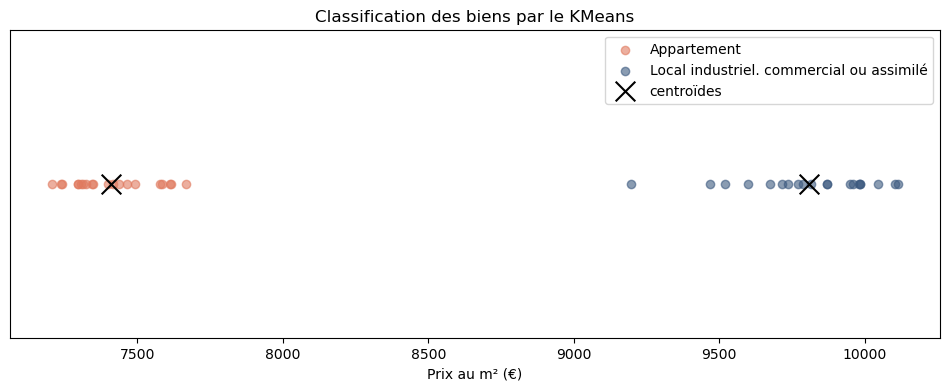

In [87]:
plt.figure(figsize=(12,4))
for type_bien, couleur in [('Appartement', '#E07A5F'), ('Local industriel. commercial ou assimilé', '#3D5A80')]:
    sous_groupe = df_kmeans[df_kmeans['type_local_predit'] == type_bien]
    plt.scatter(sous_groupe['prix_m2'], [0] * len(sous_groupe), color=couleur, label=type_bien, alpha=0.6)
plt.scatter(kmeans.cluster_centers_.ravel(), [0, 0], color='black', marker='x', s=200, label='centroïdes')
plt.yticks([])
plt.xlabel('Prix au m² (€)')
plt.title('Classification des biens par le KMeans')
plt.legend()
plt.show()

**Conclusion du Milestone 4 :** le KMeans sépare les 40 ventes en **deux groupes de 20** : un groupe au prix au m² plus bas (environ **7 408,78 €/m²** en moyenne, de 7 207,22 € à 7 666,07 €), classé en **appartements**, et un groupe plus cher (environ **9 806,92 €/m²**, de 9 194,70 € à 10 113,20 €), classé en **locaux commerciaux**. La séparation est très nette : **aucune vente** entre 7 666 € et 9 195 €/m², soit un écart de plus de 1 500 €/m² entre les deux groupes, cohérent avec l'écart observé au Milestone 1.

*Validation de la méthode : testée sur les 241 ventes 2021 du 19e de l'historique, dont on connaît le vrai type, elle retrouve le bon type dans 100 % des cas.*

**Limites** : on ne connaît pas le vrai type de ces 40 biens, on ne peut donc pas vérifier directement le résultat. La méthode suppose qu'un local est toujours plus cher au m² qu'un appartement **du même arrondissement** : sur toutes les ventes 2021 de Paris, elle ne classe correctement qu'environ 80 % des biens, car un appartement d'un quartier cher peut coûter plus au m² qu'un local d'un quartier moins cher.

# Milestone 5 - Analyse et présentation des résultats

**Synthèse des résultats :**
- **Le marché (Milestone 1)** : de 2017 à 2021, le prix moyen au m² des appartements parisiens est passé d'environ 9 500 € à 10 450 €, avec un pic en 2020 et un léger repli en 2021. Le prix dépend fortement de **l'arrondissement** (environ 5 000 €/m² d'écart entre le centre et le nord-est), de **la surface**, de **la date** et du **type de bien** (les locaux commerciaux sont environ 1 500 €/m² plus chers que les appartements).
- **Le modèle (Milestone 2)** : la régression linéaire prédit la valeur d'un bien avec une erreur moyenne de **8,93 %** (séparation au hasard), sous l'objectif de 10 %. En lui faisant prédire le **prix au m²**, l'erreur descend à **2,61 %**. Testée dans l'ordre du temps, elle ferait 16,72 % : elle prolonge la hausse passée et surestime les prix quand le marché se stabilise.
- **Le portefeuille (Milestone 3)** : au 31 décembre 2022, le **segment corporate** serait valorisé à environ **98,32 M€**, contre **71,24 M€** pour le **segment particulier** (et respectivement 97,30 M€ et 69,42 M€ avec le modèle « prix au m² »). C'est donc le segment corporate qui aura la plus grande valorisation, et cette conclusion est confirmée par un second modèle.
- **La classification (Milestone 4)** : le KMeans répartit les 40 biens à classer en 20 appartements (environ 7 409 €/m²) et 20 locaux commerciaux (environ 9 807 €/m²), à partir de leur seul prix au m².

Mes conclusions sur l'analyse et les limites de l'exercice :
- **Les chiffres sont des estimations, pas des certitudes.** Chaque prédiction individuelle peut s'écarter d'environ 9 % en moyenne, et davantage quand le marché change de tendance. La valorisation globale est plus fiable, car les erreurs se compensent en partie, mais elle reste un ordre de grandeur. De plus, la prédiction pour fin 2022 **prolonge la tendance passée** : un retournement du marché (hausse des taux d'intérêt, par exemple) la rendrait trop optimiste.
- **Les données sont limitées** : le modèle ne connaît ni l'état du bien, ni l'étage, ni la présence d'un ascenseur ou d'un extérieur, qui comptent beaucoup dans le prix réel. Les locaux commerciaux ne représentent que 7 % de l'historique. Enfin, la classification KMeans repose sur l'hypothèse qu'un local est toujours plus cher au m² qu'un appartement du même arrondissement, ce qui n'est pas forcément vrai partout. Pour aller plus loin, on pourrait enrichir les données, tester d'autres algorithmes et mettre à jour le modèle avec les ventes de 2022.